# Modelo original: ATER

**ATER** = *Agregación de expertos por régimen horario y Térmico con corrección de nivel En línea y Relativa*.

## Motivación
Los capítulos de benchmarks dejaron tres hechos:

1. El random forest y el XGBoost relativos están **empatados** y se alternan el primer lugar de un fold a otro: ninguno domina siempre.
2. El mejor modelo **cambia según la hora**: de madrugada la demanda es casi la de ayer; a las 15:00 con calor fuerte pesan las interacciones no lineales.
3. La demanda **sube sin parar** (17,5 % en cuatro años): un modelo entrenado una vez se va quedando corto en nivel durante los 21 meses de prueba.

ATER no entrena un modelo más: aprende **a quién creerle, a qué hora y con cuánto calor**, y corrige el nivel cada día con lo que acaba de pasar. Usa como expertos los cinco pronósticos ya conocidos (random forest, XGBoost, híbrido, Ridge y persistencia) y una regla de combinación propia.

## Formulación
Sea $f_{k,t}$ el pronóstico del experto $k \in \{1,\dots,K\}$ para la hora $t$, $h(t)\in\{0,\dots,23\}$ la hora del día, $c_t$ el índice de calor conocido al emitir (°C), $n_t$ el nivel (media de los 7 días anteriores, MWh) y $y_t$ la demanda real. La pérdida **relativa** del experto $k$ en $t$, acotada a $[0,1]$, es

$$\ell_{k,t} = \min\left\{1,\; \left(\frac{(1+b_{h(t)})\,f_{k,t} - y_t}{n_t}\right)^2\right\}$$ (eq-perdida)

ATER guarda, para cada hora $h$ y cada banda de calor $j$ (centros $\tau_j$ = 20, 21, …, 47 °C), la pérdida acumulada con olvido $\lambda$:

$$S_{h,j,k} \leftarrow \lambda\, S_{h,j,k} + \sum_{t \in \text{día},\, h(t)=h,\, \text{banda}(c_t)=j} \ell_{k,t}$$ (eq-acumulador)

Para pronosticar la hora $t$ suaviza esas pérdidas con un núcleo gaussiano sobre el calor y calcula pesos exponenciales:

$$L_{k,t} = \sum_j e^{-\frac{(c_t-\tau_j)^2}{2\sigma^2}}\, S_{h(t),j,k}, \qquad w_{k,t} = \frac{e^{-\eta L_{k,t}}}{\sum_{i=1}^K e^{-\eta L_{i,t}}}$$ (eq-pesos)

El pronóstico combina los expertos y aplica una corrección multiplicativa de nivel por hora:

$$\hat y_t = (1 + b_{h(t)}) \sum_{k=1}^K w_{k,t}\, f_{k,t}$$ (eq-pronostico)

Al cierre de cada día, $b_h$ se actualiza por **descenso de gradiente en línea** sobre la pérdida relativa $g(b)=\left((1+b)\bar f_t - y_t\right)^2/n_t^2$, con $\bar f_t=\sum_k w_{k,t} f_{k,t}$:

$$\frac{\partial g}{\partial b} = \frac{2\,(\hat y_t - y_t)\,\bar f_t}{n_t^2}, \qquad b_h \leftarrow b_h - \eta_b \sum_{t:\,h(t)=h} \frac{2\,(\hat y_t - y_t)\,\bar f_t}{n_t^2}$$ (eq-nivel)

**Hiperparámetros propios:** $\eta$ (tasa de los pesos), $\lambda$ (olvido), $\sigma$ (ancho del núcleo de calor, °C) y $\eta_b$ (tasa de la corrección de nivel).

**Sin fuga de información.** El pronóstico del día $D+1$ se emite al final del día $D$ y solo usa pérdidas hasta el día $D$. ATER no necesita $y$ para pronosticar: la demanda real del día $D$ es el `lag24` de las filas del día $D+1$, que ya está en las predictoras (y una prueba unitaria verifica que cambiar la demanda de un día no cambia los pronósticos de ese mismo día).

## Pseudocódigo

```text
Entradas : pronósticos de K expertos f[t,k], hora h[t], índice de calor c[t], nivel n[t],
           demanda real y[t] (se conoce al cierre de cada día), hiperparámetros η, λ, σ, η_b
Salida   : pronósticos ŷ[t]
Estado   : S[24, B, K] ← 0      (pérdidas acumuladas por hora, banda de calor y experto)
           b[24]       ← 0      (corrección de nivel por hora)

para cada día d en orden cronológico:
    # 1) pronóstico del día completo (emitido al cierre del día anterior)
    para cada hora t del día d:
        κ[j]   ← exp(-(c[t] - τ[j])² / (2σ²))                      para j = 1..B
        L[k]   ← Σ_j κ[j] · S[h[t], j, k]                           para k = 1..K
        w[k]   ← exp(-η (L[k] - min L)) / Σ_i exp(-η (L[i] - min L))
        f̄      ← Σ_k w[k] f[t,k]
        ŷ[t]   ← (1 + b[h[t]]) · f̄
    # 2) actualización al cierre del día d (cuando se conoce y)
    S ← λ · S
    para cada hora t del día d:
        ℓ[k]   ← min(1, (((1 + b[h[t]]) f[t,k] - y[t]) / n[t])²)    para k = 1..K
        S[h[t], banda(c[t]), :] += ℓ
        b[h[t]] ← b[h[t]] - η_b · 2 (ŷ[t] - y[t]) f̄ / n[t]²
devolver ŷ
Criterio de parada: se recorre cada día una sola vez (algoritmo en línea, una pasada).
```

## Sustento teórico

**Propiedad 1 (cota de arrepentimiento de los pesos).** Para un régimen fijo (una hora, sin núcleo de calor: $\sigma=\infty$, sin olvido: $\lambda=1$) la regla [](eq-pesos) es el pronosticador de pesos exponenciales (*Hedge*). Con pérdidas en $[0,1]$ —por eso la pérdida [](eq-perdida) se acota—, después de $T$ rondas

$$\sum_{t=1}^T \sum_k w_{k,t}\ell_{k,t} - \min_k \sum_{t=1}^T \ell_{k,t} \;\le\; \frac{\ln K}{\eta} + \frac{\eta\, T}{8}$$ (eq-cota)

(Cesa-Bianchi y Lugosi, 2006, teorema 2.2). *Esquema de la prueba:* con el potencial $\Phi_t=\frac{1}{\eta}\ln\sum_k e^{-\eta L_{k,t}}$, el lema de Hoeffding da $\Phi_{t}-\Phi_{t-1}\le -\sum_k w_{k,t}\ell_{k,t}+\eta/8$; sumando y usando $\Phi_0=\frac{\ln K}{\eta}$ y $\Phi_T\ge -\min_k L_{k,T}$ se obtiene [](eq-cota). Con $\eta^*=\sqrt{8\ln K/T}$ la cota es $\sqrt{T\ln K/2}$: el arrepentimiento promedio tiende a cero. El núcleo y el olvido convierten la regla en una versión *local* (en calor) y *de seguimiento* (en el tiempo) de Hedge; la cota exacta para esas variantes no se demuestra aquí y se verifica empíricamente abajo.

**Propiedad 2 (convexidad de la corrección de nivel).** $g(b)$ es una parábola en $b$ con $g''(b)=2\bar f_t^2/n_t^2>0$: es convexa, y [](eq-nivel) es descenso de gradiente en línea, que con paso decreciente $\eta_b\propto 1/\sqrt{t}$ tiene arrepentimiento $O(\sqrt T)$ (Zinkevich, 2003). Con paso constante sigue un sesgo que cambia en el tiempo, que es lo que se necesita con una demanda que crece. La prueba unitaria `test_correccion_de_nivel_aprende_un_sesgo` verifica que $b_h$ converge a un sesgo conocido de +5 %.

**Propiedad 3 (complejidad).** Por hora pronosticada: el núcleo cuesta $O(B)$, las pérdidas suavizadas $O(BK)$ y la actualización $O(K)$. Total $O(n\,B\,K)$ en tiempo y $O(24\,B\,K)$ en memoria (independiente de $n$). Con $B=28$ bandas y $K=5$, el estado ocupa 3.360 números. El entrenamiento cuesta lo que cuestan los expertos; el núcleo agrega una pasada lineal.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src"); import estilo_tablas; estilo_tablas.activar()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)
R = "../resultados/"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
ORIG = "ATER (modelo original)"
COL = {"Persistencia (misma hora de ayer)": "#9AA5A0", "Estacional (misma hora semana pasada)": "#B8C2BD", "Promedio por hora y día": "#D5DBD8",
       "Ridge (lineal)": "#5B7F96", "Random forest (relativo)": "#1F5A3A", "XGBoost (relativo)": "#C8892B",
       "Híbrido Ridge + XGBoost (residuo relativo)": "#8E4B7A", ORIG: "#C0392B"}

In [2]:
# Verificación empírica de la Propiedad 1 en la prueba: Hedge puro por hora (σ = ∞, λ = 1, η_b = 0)
import joblib
from original_model import AgregacionTermica, ModeloOriginal
import pipeline_energia as P
df = pd.read_pickle(R + "datos_horarios.pkl"); X, y = P.construir(df); ok = X.notna().all(axis=1); X, y = X[ok], y[ok]
Xte = X[X.index >= pd.Timestamp("2025-01-01")]
mo = joblib.load("../artifacts/ater_modelo_original.joblib")
F = mo.pronosticos_expertos(Xte); M = mo._matriz(Xte, F); yr = ModeloOriginal.realizado(Xte); yv = y[Xte.index].values
par = json.load(open(R + "orig_hiperparametros.json"))["hiperparametros"]
h = AgregacionTermica(eta=par["eta"], lam=1.0, sigma=np.inf, eta_b=0.0).iniciar_vacio(F.shape[1])
p = h.predict(M, yr, guardar_pesos=True); W = h.historia_pesos_
ell = np.minimum(((F - yv[:, None]) / Xte.media_7d.values[:, None]) ** 2, 1)
filas = []
for hr in range(24):
    s = Xte.hora.values == hr; T = s.sum()
    reg = (W[s] * ell[s]).sum() - ell[s].sum(0).min()
    filas.append(dict(hora=hr, T=T, arrepentimiento=reg, cota=np.log(F.shape[1]) / par["eta"] + par["eta"] * T / 8))
reg = pd.DataFrame(filas)
print("Horas en que el arrepentimiento empírico es menor que la cota teórica: %d de 24" % (reg.arrepentimiento <= reg.cota).sum())
print("Arrepentimiento empírico medio por hora: %.4f | negativo (mejor que el mejor experto fijo) en %d de 24 horas" % (reg.arrepentimiento.mean(), (reg.arrepentimiento < 0).sum()))
reg.round(4).head(6)

Horas en que el arrepentimiento empírico es menor que la cota teórica: 24 de 24
Arrepentimiento empírico medio por hora: 0.0252 | negativo (mejor que el mejor experto fijo) en 0 de 24 horas


hora,T,arrepentimiento,cota
0,653,0.020500,7296.006200
1,653,0.020300,7296.006200
2,653,0.019600,7296.006200
3,653,0.018300,7296.006200
4,653,0.019400,7296.006200
5,653,0.010700,7296.006200


**Lectura.** La cota [](eq-cota) se cumple en las 24 horas, pero es muy holgada: con el $\eta$ que eligió Optuna para minimizar el error (no para optimizar la cota) el término $\eta T/8$ domina. El arrepentimiento empírico frente al **mejor experto fijo elegido a posteriori** es positivo pero mínimo: 0,025 unidades de pérdida relativa acumuladas en 653 días por hora, del orden de $4\times10^{-5}$ por día. En la práctica, ese "mejor experto fijo" no se conoce de antemano, y la versión completa de ATER (con corrección de nivel) le gana al mejor experto individual en la prueba (ablación, abajo).

K =  2: pendiente log(tiempo) vs log(n) = 0.97 (teoría: 1, lineal)
K =  5: pendiente log(tiempo) vs log(n) = 1.23 (teoría: 1, lineal)
K = 10: pendiente log(tiempo) vs log(n) = 0.97 (teoría: 1, lineal)


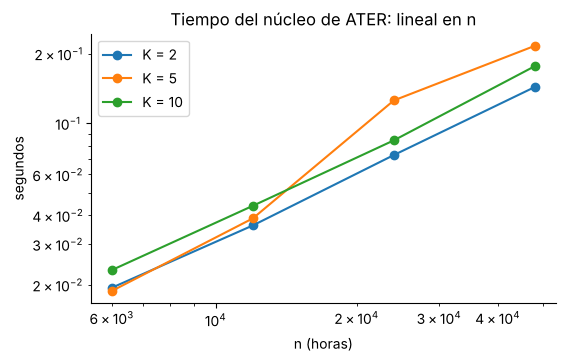

In [3]:
# Complejidad empírica: tiempo del núcleo al variar n (horas) y K (expertos)
import time
rng = np.random.default_rng(0); filas = []
for K in [2, 5, 10]:
    for dias in [250, 500, 1000, 2000]:
        n = dias * 24; hora = np.tile(np.arange(24), dias); dia = np.repeat(np.arange(dias), 24)
        Fs = 1000 + rng.normal(0, 50, (n, K)); ys = 1000 + rng.normal(0, 30, n)
        Ms = np.column_stack([hora, rng.uniform(22, 45, n), np.full(n, 1000.0), dia, Fs])
        m = AgregacionTermica().iniciar_vacio(K); t0 = time.perf_counter(); m.predict(Ms, ys); filas.append(dict(K=K, n=n, segundos=time.perf_counter() - t0))
cx = pd.DataFrame(filas)
for K, g in cx.groupby("K"):
    pend = np.polyfit(np.log(g.n), np.log(g.segundos), 1)[0]; print(f"K = {K:2d}: pendiente log(tiempo) vs log(n) = {pend:.2f} (teoría: 1, lineal)")
fig, ax = plt.subplots(figsize=(6, 3.5))
for K, g in cx.groupby("K"): ax.loglog(g.n, g.segundos, "o-", label=f"K = {K}")
ax.set_xlabel("n (horas)"); ax.set_ylabel("segundos"); ax.set_title("Tiempo del núcleo de ATER: lineal en n"); ax.legend(); plt.show()

## Código
La implementación completa está en `src/original_model.py` (clases `AgregacionTermica`, el núcleo en numpy, y `ModeloOriginal`, que entrena los expertos). Estas son las tres piezas del algoritmo:

In [4]:
import inspect
from original_model import AgregacionTermica
for f in [AgregacionTermica._pesos, AgregacionTermica._actualizar, AgregacionTermica._recorrer]:
    print(inspect.getsource(f))

    def _pesos(self, r, c):
        """Pesos exponenciales w (m, K) para las filas con régimen horario r y calor c."""
        c = np.clip(c, self.bandas_[0], self.bandas_[-1])
        if np.isinf(self.sigma):
            Kc = np.ones((len(c), len(self.bandas_)))
        else:
            Kc = np.exp(-0.5 * ((c[:, None] - self.bandas_[None, :]) / self.sigma) ** 2)
        L = np.einsum("mb,mbk->mk", Kc, self.S_[r])
        W = np.exp(-self.eta * (L - L.min(axis=1, keepdims=True)))   # restar el mínimo: estabilidad numérica
        return W / W.sum(axis=1, keepdims=True)

    def _actualizar(self, Fd, yd, r, c, nivel, comb, p):
        ell = np.minimum(((Fd * (1.0 + self.b_[r])[:, None] - yd[:, None]) / nivel[:, None]) ** 2, 1.0)
        self.S_ *= self.lam
        cb = np.clip(np.round((np.clip(c, self.bandas_[0], self.bandas_[-1]) - self.bandas_[0]) / self.paso).astype(int),
                     0, len(self.bandas_) - 1)
        np.add.at(self.S_, (r, cb), ell)
        if self.eta_b >

## Pruebas unitarias
`tests/test_original_model.py` verifica: (i) que el modelo aprende en un problema sintético con solución conocida (los pesos se concentran en el experto exacto; la corrección de nivel recupera un sesgo de +5 %; con $\eta=\eta_b=0$ es exactamente el promedio), (ii) la reproducibilidad y que `predict` no altera el estado, (iii) el manejo de entradas e hiperparámetros inválidos, (iv) la compatibilidad con `sklearn.base.clone`, y además que **no usa el futuro**.

In [5]:
import subprocess
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "../tests", "-p", "no:cacheprovider"], capture_output=True, text=True)
print(out.stdout[-1500:])

.............                                                            [100%]
13 passed in 1.16s



## Optimización de hiperparámetros (bayesiana)
Los cuatro hiperparámetros de ATER se optimizan con **Optuna (TPE, bayesiano)**, 80 ensayos, semilla 2026, minimizando el MSE medio de los 5 folds de validación (los mismos folds, la misma purga y la misma semilla que los benchmarks). En la validación anidada del capítulo 6, la optimización se repite dentro de cada fold externo (60 ensayos) usando solo los folds anteriores.

{'hiperparametros': {'eta': 89.38423554574598, 'lam': 0.9657109024109057, 'sigma': 5.068873602673464, 'eta_b': 0.00796538678948261}, 'mse_validacion': 1976.7348823141806, 'metodo': 'Optuna TPE (bayesiano), 80 ensayos, semilla 2026'}


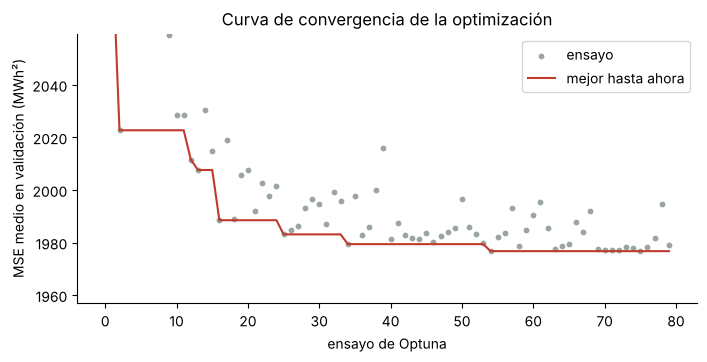

In [6]:
tri = pd.read_csv(R + "orig_optuna_trials.csv"); hp = json.load(open(R + "orig_hiperparametros.json")); print(hp)
fig, ax = plt.subplots(figsize=(8, 3.5)); ax.scatter(tri.number, tri.value, s=10, color="#9AA5A0", label="ensayo")
ax.plot(tri.number, tri.mejor_hasta_ahora, color="#C0392B", label="mejor hasta ahora"); ax.set_ylim(tri.value.min() * .99, tri.value.quantile(.9))
ax.set_xlabel("ensayo de Optuna"); ax.set_ylabel("MSE medio en validación (MWh²)"); ax.set_title("Curva de convergencia de la optimización"); ax.legend(); plt.show()

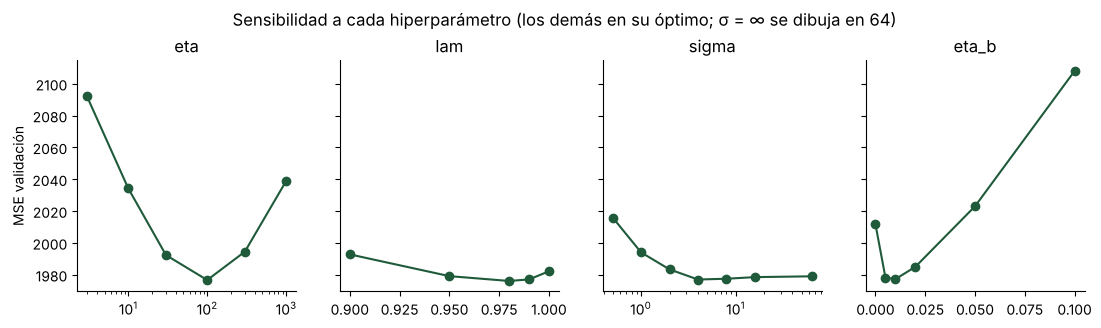

valor,0.000000,0.005000,0.010000,0.020000,0.050000,0.100000,0.500000,0.900000,0.950000,0.980000,0.990000,1.000000,2.000000,3.000000,4.000000,8.000000,10.000000,16.000000,30.000000,100.000000,300.000000,1000.000000,inf
parametro,,,,,,,,,,,,,,,,,,,,,,,
eta,,,,,,,,,,,,,,2.092,,,2.034,,1.992,1.977,1.994,2.039,
eta_b,2.012,1.978,1.977,1.985,2.023,2.108,,,,,,,,,,,,,,,,,
lam,,,,,,,,1.993,1.979,1.976,1.977,1.982,,,,,,,,,,,
sigma,,,,,,,2.016,,,,,1.994,1.983,,1.977,1.978,,1.978,,,,,1.979


In [7]:
sen = pd.read_csv(R + "orig_sensibilidad.csv")
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, (nom, g) in zip(axs, sen.groupby("parametro", sort=False)):
    xv = g.valor.replace(np.inf, 64) ; ax.plot(xv, g.MSE_val, "o-", color="#1F5A3A"); ax.set_title(nom)
    if nom in ("eta", "sigma"): ax.set_xscale("log")
axs[0].set_ylabel("MSE validación"); plt.suptitle("Sensibilidad a cada hiperparámetro (los demás en su óptimo; σ = ∞ se dibuja en 64)", y=1.05); plt.show()
sen.pivot_table(index="parametro", columns="valor", values="MSE_val").round(1)

**Lectura.** El MSE de validación es plano alrededor del óptimo para $\lambda$ y $\sigma$ y tiene un mínimo claro en $\eta$ (entre 30 y 300) y en $\eta_b$ (alrededor de 0,01): los dos hiperparámetros que importan son la tasa de los pesos y la de la corrección de nivel. Que $\sigma$ dé casi lo mismo con 4 °C que con $\infty$ anticipa el resultado de la ablación.

## Estudio de ablación
Se retira cada componente por separado (con los demás hiperparámetros fijos) y se compara con reglas estándar de combinación ajustadas en validación: promedio simple, pesos por error global ($1/\text{MSE}$), *stacking* lineal no negativo y *stacking* por mínimos cuadrados.

In [8]:
ab = pd.read_csv(R + "orig_ablacion.csv"); ab.round(2)

variante,grupo,MSE_prueba,MAPE_prueba,MSE_validacion,cambio_MSE_vs_completo_%
ATER completo,componente,2.256,"2,44",1.977,"0,00"
sin régimen térmico (sigma = ∞),componente,2.254,"2,43",1.979,"-0,09"
sin corrección de nivel (eta_b = 0),componente,2.315,"2,55",2.012,"2,61"
sin régimen horario (pesos comunes),componente,2.434,"2,58",2.215,"7,88"
sin pesos aprendidos (eta = 0),componente,2.461,"2,60",2.143,"9,08"
sin olvido (lambda = 1),componente,2.247,"2,42",1.982,"-0,39"
"promedio simple (eta = 0, eta_b = 0)",componente,2.612,"2,77",2.166,"15,78"
sin el experto Random forest (relativo),experto,2.314,"2,49",1.993,"2,58"
sin el experto XGBoost (relativo),experto,2.291,"2,48",1.995,"1,54"
sin el experto Híbrido Ridge + XGBoost (residuo relativo),experto,2.271,"2,44",2.018,"0,68"


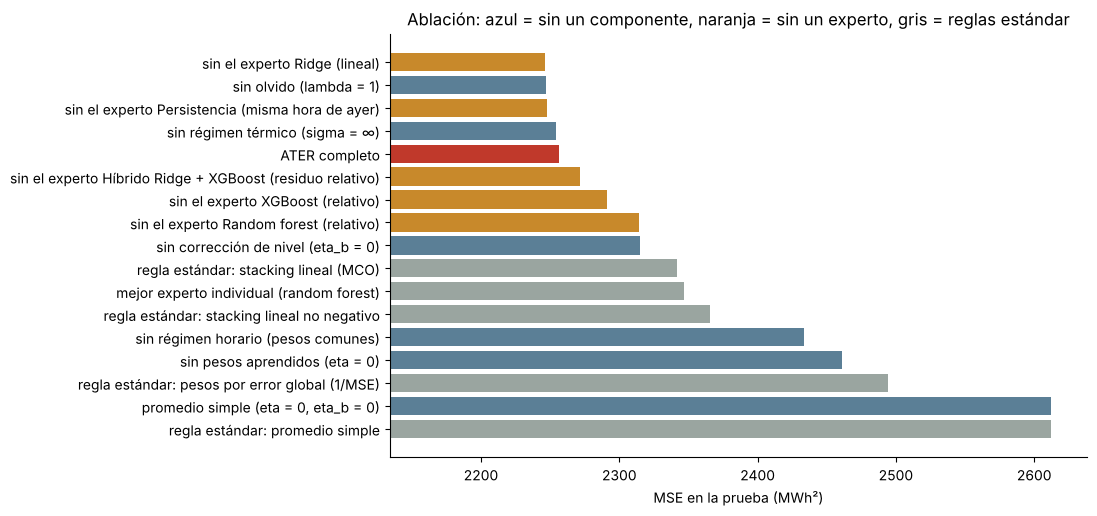

In [9]:
a = ab.sort_values("MSE_prueba"); fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(a.variante, a.MSE_prueba, color=["#C0392B" if v == "ATER completo" else "#5B7F96" if g == "componente" else "#C8892B" if g == "experto" else "#9AA5A0" for v, g in zip(a.variante, a.grupo)])
ax.invert_yaxis(); ax.set_xlim(a.MSE_prueba.min() * .95, a.MSE_prueba.max() * 1.01); ax.set_xlabel("MSE en la prueba (MWh²)")
ax.set_title("Ablación: azul = sin un componente, naranja = sin un experto, gris = reglas estándar"); plt.show()

**Lectura de la ablación.**

- **Lo que aporta:** los **pesos por hora** son el componente más valioso: con pesos comunes a todas las horas el MSE sube 7,9 %, y sin pesos aprendidos ($\eta=0$) sube 9,1 %. La **corrección de nivel en línea** aporta 2,6 % (sin ella, 2.315 en lugar de 2.256).
- **Lo que no aporta:** el **núcleo de calor** no mejora nada medible (sin él el MSE cambia −0,1 % en la prueba y +0,1 % en validación) y tampoco el olvido ($\lambda=1$ da −0,4 %). El calor de Sabanagrande ya lo usan los expertos (por eso es tan importante en los árboles); ATER no gana nada separando los pesos por calor. Se mantiene en la formulación porque Optuna lo eligió en validación, pero **el aporte original medible está en el régimen horario y en la corrección de nivel**, no en el régimen térmico.
- **Frente a las reglas estándar:** ATER (2.256) le gana al *stacking* por mínimos cuadrados (2.341), al *stacking* no negativo (2.366), a los pesos por error global (2.494), al promedio simple (2.612) y al mejor experto solo (random forest, 2.347). Ninguna regla de pesos fijos alcanza a una regla que se adapta cada día.
- **Expertos:** quitar el random forest es lo que más daño hace (+2,6 %), luego el XGBoost (+1,5 %). Quitar Ridge o la persistencia no empeora: ATER aprende a casi no usarlos.

## ¿A quién le cree ATER, y a qué hora?

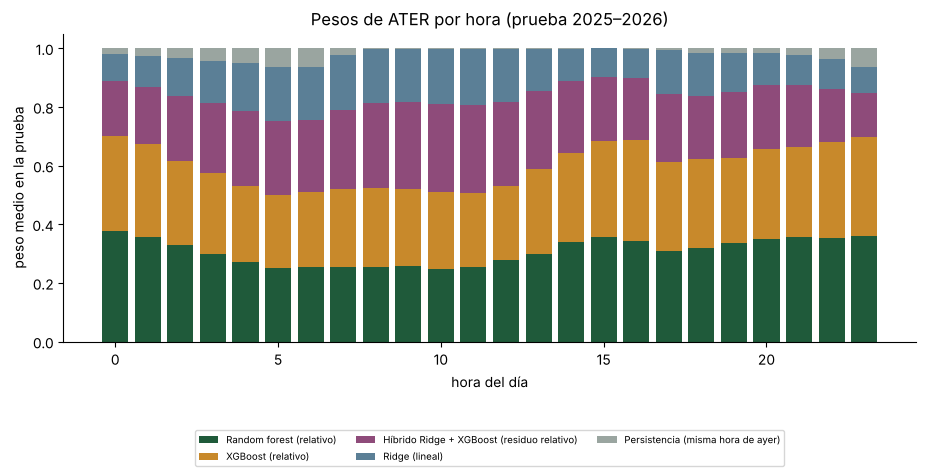

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Random forest (relativo),"0,380","0,360","0,330","0,300","0,270","0,250","0,250","0,250","0,250","0,260","0,250","0,250","0,280","0,300","0,340","0,360","0,340","0,310","0,320","0,340","0,350","0,360","0,350","0,360"
XGBoost (relativo),"0,330","0,320","0,290","0,280","0,260","0,250","0,250","0,260","0,270","0,260","0,260","0,250","0,260","0,290","0,300","0,330","0,340","0,310","0,300","0,290","0,310","0,310","0,330","0,340"
Híbrido Ridge + XGBoost (residuo relativo),"0,190","0,200","0,220","0,240","0,250","0,250","0,250","0,270","0,290","0,300","0,300","0,300","0,290","0,270","0,250","0,220","0,210","0,230","0,220","0,230","0,220","0,210","0,180","0,150"
Ridge (lineal),"0,090","0,110","0,130","0,140","0,160","0,180","0,180","0,190","0,190","0,180","0,190","0,190","0,180","0,140","0,110","0,100","0,100","0,150","0,150","0,130","0,110","0,100","0,100","0,090"
Persistencia (misma hora de ayer),"0,020","0,030","0,030","0,040","0,050","0,060","0,070","0,020","0,000","0,000","0,000","0,000","0,000","0,000","0,000","0,000","0,000","0,010","0,020","0,020","0,020","0,020","0,040","0,060"


In [10]:
Wp = pd.read_pickle(R + "orig_pesos_prueba.pkl"); wm = Wp.groupby(Wp.index.hour).mean()
fig, ax = plt.subplots(figsize=(11, 4)); bottom = np.zeros(24)
for c in wm.columns: ax.bar(wm.index, wm[c], bottom=bottom, label=c, color=COL[c]); bottom += wm[c].values
ax.set_xlabel("hora del día"); ax.set_ylabel("peso medio en la prueba"); ax.set_title("Pesos de ATER por hora (prueba 2025–2026)"); ax.legend(fontsize=7, ncol=3, loc="lower center", bbox_to_anchor=(.5, -.42)); plt.show()
wm.round(2).T

**Lectura.** ATER le cree sobre todo a los dos árboles relativos (entre 50 y 71 % del peso según la hora). De día (7–12 h) le sube el peso al híbrido (hasta 30 %) y a Ridge (hasta 19 %), que capturan mejor la rampa de la mañana. La persistencia casi no recibe peso (como máximo 7 % de madrugada). Esto explica la ablación: quitar Ridge o la persistencia no empeora el error, pero quitar un árbol sí.

## Interpretabilidad (SHAP)
Valores SHAP con el explicador por permutación de `shap` (independiente del modelo), para ATER (estado congelado al final de la prueba) y para el mejor benchmark (random forest relativo), sobre las mismas 150 horas de la prueba y el mismo fondo de 50 horas de entrenamiento.

Correlación de Spearman entre las importancias de ATER y del RF: 0.86


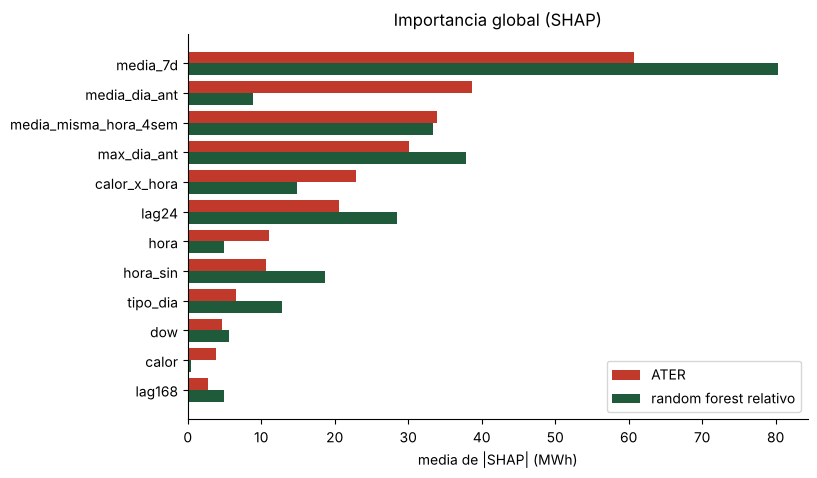

,ATER_media_abs_SHAP_MWh,RF_media_abs_SHAP_MWh,rank_ATER,rank_RF
media_7d,60.670000,80.350000,1,1
media_dia_ant,38.730000,8.880000,2,8
media_misma_hora_4sem,33.920000,33.370000,3,3
max_dia_ant,30.140000,37.800000,4,2
calor_x_hora,22.840000,14.800000,5,6
lag24,20.610000,28.510000,6,4
hora,11.040000,4.910000,7,11
hora_sin,10.710000,18.670000,8,5
tipo_dia,6.630000,12.770000,9,7
dow,4.610000,5.550000,10,9


In [11]:
imp = pd.read_csv(R + "shap_importancia_global.csv", index_col=0)
from scipy.stats import spearmanr
print("Correlación de Spearman entre las importancias de ATER y del RF: %.2f" % spearmanr(imp.iloc[:, 0], imp.iloc[:, 1])[0])
top = imp.head(12).iloc[::-1]; fig, ax = plt.subplots(figsize=(8, 5)); yy = np.arange(len(top))
ax.barh(yy + .2, top.ATER_media_abs_SHAP_MWh, .4, color="#C0392B", label="ATER"); ax.barh(yy - .2, top.RF_media_abs_SHAP_MWh, .4, color="#1F5A3A", label="random forest relativo")
ax.set_yticks(yy); ax.set_yticklabels(top.index); ax.set_xlabel("media de |SHAP| (MWh)"); ax.legend(); ax.set_title("Importancia global (SHAP)"); plt.show()
imp.head(12).round(2)

**Lectura.** Los dos modelos usan la información de forma parecida (correlación de Spearman de 0,86 entre las importancias): primero el **nivel reciente** (media de 7 días, media de ayer, misma hora de las últimas 4 semanas, máximo de ayer), luego la **interacción calor × hora** y la misma hora de ayer. La diferencia es que en ATER la media de ayer y la interacción calor × hora pesan más que en el random forest: es el efecto de mezclar al random forest con el XGBoost y el híbrido, que usan más esas variables.